# Regression WiSARD e Regression WiSARD com filtro de Kalman

Notebook autocontido. Todo o código dos modelos está aqui dentro, na ordem em
que é usado, para que o caminho da entrada até a predição possa ser lido de cima
para baixo sem abrir nenhum outro arquivo.

**O que este notebook faz, em ordem:**

1. Implementa a codificação de entrada (thermometer) e o endereçamento (retina e mapping)
2. Implementa a **Regression WiSARD** (ReW), fiel à referência oficial
3. Verifica a implementação contra um exemplo calculado na mão
4. Roda a ReW no House Prices e mostra **como** ela erra
5. Implementa a **Kalman-ReW**, com filtro nos dois estados da célula
6. Compara as duas com tabelas e gráficos

**A pergunta:** o filtro de Kalman melhora a Regression WiSARD, e por qual
mecanismo?

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

plt.rcParams.update({
    "figure.dpi": 110, "font.size": 9, "axes.grid": True,
    "grid.alpha": .25, "axes.spines.top": False, "axes.spines.right": False,
})

# paleta usada em todo o notebook
COR_REW  = "#B4674D"   # ReW pura
COR_KAL  = "#2F6B6A"   # Kalman-ReW
COR_REF  = "#8A8F98"   # referências e limites

SEEDS = [0, 1, 2, 3, 4]   # subir para range(30) na bateria final da dissertação
ADDRESS_SIZE = 17         # bits por RAM node. Valor publicado no ESANN 2019
RESOLUTION   = 16         # bits de thermometer por atributo

---
## 1. Codificação da entrada: thermometer

A WiSARD não recebe números, recebe bits. O thermometer converte um atributo
numérico numa sequência de bits acendendo mais bits quanto maior o valor:

```
valor baixo  →  0 0 0 0 0 0
valor médio  →  1 1 1 0 0 0
valor alto   →  1 1 1 1 1 0
```

É uma codificação **monotônica**: preserva a noção de ordem, ao contrário de uma
codificação binária pura, onde 7 (`0111`) e 8 (`1000`) diferem em todos os bits
apesar de serem vizinhos.

A fórmula é `k = int((valor − mínimo) / faixa × resolução)`, e `k` é quantos bits
acendem. O mínimo e o máximo vêm **só do conjunto de treino**: calcular no
dataset inteiro vazaria informação do teste.

In [2]:
class ThermometerEncoder:
    """Codifica uma coluna numérica em `resolution` bits monotônicos."""

    def __init__(self, minimum, maximum, resolution):
        self.minimum, self.maximum, self.resolution = minimum, maximum, resolution
        # o +1e-9 evita divisão por zero em coluna constante. Efeito colateral:
        # o valor máximo nunca acende TODOS os bits (fica em resolution-1).
        self._range = (maximum - minimum) + 1e-9

    def encode(self, column):
        col = np.clip(column, self.minimum, self.maximum)
        k = np.clip(((col - self.minimum) / self._range * self.resolution).astype(int),
                    0, self.resolution)
        return (np.arange(self.resolution) < k[:, np.newaxis]).astype(np.uint8)


def build_encoders(X, resolution):
    """Um encoder por coluna. Recebe SOMENTE o treino."""
    mins, maxs = X.min(axis=0), X.max(axis=0)
    return [ThermometerEncoder(mins[j], maxs[j], resolution) for j in range(X.shape[1])]


def apply_encoders(X, encoders):
    """Concatena os bits de todas as colunas: esse vetor é a retina."""
    return np.concatenate([e.encode(X[:, j]) for j, e in enumerate(encoders)], axis=1)


# demonstração: metragem de casas, 6 bits
demo = np.array([[1200.], [1800.], [3000.], [900.], [3800.]])
encs = build_encoders(demo, 6)
for v, bits in zip(demo[:, 0], apply_encoders(demo, encs)):
    print(f"  {v:6.0f} ft²  →  {''.join(map(str, bits))}")

    1200 ft²  →  000000
    1800 ft²  →  100000
    3000 ft²  →  111100
     900 ft²  →  000000
    3800 ft²  →  111110


---
## 2. Endereçamento: retina, mapping e RAM nodes

A retina é o vetor de bits inteiro, resultado de concatenar todos os atributos
codificados. Seu tamanho é `n_features × resolution`.

Três coisas acontecem com ela:

**O mapping.** Uma permutação pseudo-aleatória dos índices da retina, sorteada
uma única vez e usada para sempre. Ela existe para que cada RAM node veja uma
combinação de bits vindos de atributos **diferentes**, e não um bloco contíguo de
um atributo só. É isso que permite ao modelo capturar interação entre atributos.

**A divisão.** O vetor embaralhado é cortado em pedaços de `address_size` bits.
Cada pedaço alimenta uma RAM node. O número de RAM nodes é
`N = retina_size / address_size`.

**A conversão em endereço.** Cada pedaço de bits vira um número inteiro. A
referência monta esse número **LSB-first**: o primeiro bit da tupla tem peso 1, o
segundo peso 2, e assim por diante.

$$
a_k \;=\; \sum_{j=0}^{n-1} b_{\,\text{map}[k,j]} \cdot 2^{\,j}
$$

O sentido não muda quais exemplos caem juntos, só o rótulo do endereço, mas é
mantido igual à referência para permitir conferência numérica.

In [3]:
def monta_mapping(retina_size, address_size, rng, completa=True):
    """Permutação fixa dos bits da retina, fatiada em N grupos de address_size.

    Se retina_size não for divisível por address_size, `completa` acrescenta
    índices sorteados com reposição para fechar a última RAM node, como faz o
    `completeAddressing` do wisardpkg.
    """
    n_rams = retina_size // address_size
    resto = retina_size % address_size
    tamanho = retina_size
    if completa and resto > 0:
        n_rams += 1
        tamanho += address_size - resto

    mapping = list(range(retina_size))
    mapping += [int(rng.integers(0, retina_size)) for _ in range(tamanho - retina_size)]
    rng.shuffle(mapping)
    return np.array(mapping, dtype=int).reshape(n_rams, address_size)


def calcula_addresses(Xb, mapping, address_size):
    """Converte cada n-tupla de bits em um inteiro. LSB-first, como na referência."""
    pesos = 1 << np.arange(address_size)          # [1, 2, 4, 8, ...]
    bits = Xb[:, mapping]                          # (n_amostras, n_rams, address_size)
    return (bits * pesos).sum(axis=2).astype(int)  # (n_amostras, n_rams)


# demonstração com mapping identidade, para conferir na mão
Xb_demo = apply_encoders(demo, encs)
map_demo = np.array([[0, 1], [2, 3], [4, 5]])      # bits 1-2 → A, 3-4 → B, 5-6 → C
addr_demo = calcula_addresses(Xb_demo, map_demo, 2)

print("casa      bits      RAM A   RAM B   RAM C")
for v, b, a in zip(demo[:, 0], Xb_demo, addr_demo):
    print(f"{v:6.0f}   {''.join(map(str,b))}    {a[0]:02b}({a[0]})   {a[1]:02b}({a[1]})   {a[2]:02b}({a[2]})")

casa      bits      RAM A   RAM B   RAM C
  1200   000000    00(0)   00(0)   00(0)
  1800   100000    01(1)   00(0)   00(0)
  3000   111100    11(3)   11(3)   00(0)
   900   000000    00(0)   00(0)   00(0)
  3800   111110    11(3)   11(3)   01(1)


---
## 3. A Regression WiSARD

### O que cada célula de memória guarda

Dois números, e só existem as células que foram de fato visitadas (a memória é um
dicionário, como o `std::map` da referência):

| campo | o que é |
|---|---|
| $c_k$ | quantos exemplos de treino caíram naquele endereço |
| $S_k$ | a **soma** dos $y$ desses exemplos |

### Treino

Para cada exemplo $(x_i, y_i)$, em cada uma das $N$ RAM nodes:

$$
c_k \leftarrow c_k + 1 \qquad\qquad S_k \leftarrow S_k + y_i
$$

Sem gradiente, sem taxa de aprendizado, sem épocas. Uma passada só. E como somar
é comutativo, **a ordem dos exemplos não importa**.

### Predição

Cada RAM node devolve seu par $(c_k, S_k)$. A agregação padrão (`SimpleMean`) é:

$$
\hat{y} \;=\; \frac{\sum_k S_k}{\sum_k c_k}
$$

Como $S_k$ é uma **soma** (cresce junto com $c_k$), isso é uma média agrupada
legítima: o total de $y$ dividido pelo total de exemplos.

Guarde essa observação sobre $S_k$ ser extensiva. Ela é o motivo de essa fórmula
não transferir direto para a versão com Kalman.

In [4]:
class SimpleMean:
    """Σ S_k / Σ c_k. Agregação padrão da ReW."""
    nome = "SimpleMean (peso = contador cru)"

    def calcula(self, pares):
        soma_c = sum(c for c, _ in pares)
        soma_y = sum(s for _, s in pares)
        return soma_y / soma_c if soma_c > 0 else 0.0


class UnweightedMean:
    """Média das estimativas locais S_k/c_k, sem ponderar por contador."""
    nome = "peso uniforme"

    def calcula(self, pares):
        vals = [s / c for c, s in pares if c != 0]
        return sum(vals) / len(vals) if vals else 0.0


class RegressionWiSARD:
    def __init__(self, address_size=17, resolution=16, seed=42,
                 mean=None, mapping=None):
        self.address_size = address_size
        self.resolution = resolution
        self.mean = mean if mean is not None else SimpleMean()
        self._rng = np.random.default_rng(seed)
        self._mapping_fixo = None if mapping is None else np.asarray(mapping, dtype=int)

    # ── treino ────────────────────────────────────────────────────────────
    def fit(self, X, y):
        X, y = np.asarray(X, float), np.asarray(y, float)

        self._encoders = build_encoders(X, self.resolution)          # etapa 1
        Xb = apply_encoders(X, self._encoders)                       # etapa 2
        self.retina_size_ = Xb.shape[1]

        if self._mapping_fixo is not None:
            self._mapping = self._mapping_fixo
        else:
            self._mapping = monta_mapping(self.retina_size_, self.address_size, self._rng)
        self.n_rams_ = self._mapping.shape[0]

        addr = calcula_addresses(Xb, self._mapping, self.address_size)

        # memória esparsa: {endereço: [contador, soma_y]}, uma por RAM node
        self._memory = [dict() for _ in range(self.n_rams_)]
        for i in range(len(Xb)):
            for r in range(self.n_rams_):
                a = int(addr[i, r])
                cel = self._memory[r].get(a)
                if cel is None:
                    self._memory[r][a] = [1.0, y[i]]
                else:
                    cel[0] += 1.0
                    cel[1] += y[i]
        return self

    # ── inferência ────────────────────────────────────────────────────────
    def _le(self, X):
        """Devolve (contadores, somas), cada um (n_amostras, n_rams)."""
        Xb = apply_encoders(np.asarray(X, float), self._encoders)
        addr = calcula_addresses(Xb, self._mapping, self.address_size)
        n = len(Xb)
        cs = np.zeros((n, self.n_rams_))
        ss = np.zeros((n, self.n_rams_))
        for i in range(n):
            for r in range(self.n_rams_):
                cel = self._memory[r].get(int(addr[i, r]))
                if cel is not None:               # endereço nunca visto → (0, 0)
                    cs[i, r], ss[i, r] = cel[0], cel[1]
        return cs, ss

    def predict(self, X):
        cs, ss = self._le(X)
        return np.array([self.mean.calcula(list(zip(cs[i], ss[i]))) for i in range(len(cs))])

    # ── diagnóstico ───────────────────────────────────────────────────────
    def dont_know(self, X):
        """Fração das RAM nodes que caíram em endereço nunca visto, por amostra."""
        cs, _ = self._le(X)
        return (cs == 0).mean(axis=1)

    def addresses_usados(self):
        return np.array([len(m) for m in self._memory])

---
## 4. Verificação: cinco casas calculadas na mão

Antes de qualquer métrica, o código precisa reproduzir um exemplo conferível.
Cinco casas, uma feature (metragem), thermometer de 6 bits, address size 2,
mapping identidade.

| casa | metragem | preço |
|---|---|---|
| H1 | 1200 ft² | \$150.000 |
| H2 | 1800 ft² | \$210.000 |
| H3 | 3000 ft² | \$410.000 |
| H4 | 900 ft² | \$95.000 |
| H5 | 3800 ft² | \$520.000 |

Consulta: uma casa de 1500 ft². **Resposta esperada: \$191.250.**

In [5]:
y_toy = np.array([150000., 210000., 410000., 95000., 520000.])
toy = RegressionWiSARD(address_size=2, resolution=6, mapping=map_demo).fit(demo, y_toy)

print("MEMÓRIA APÓS O TREINO (só endereços visitados existem)\n")
for r, nome in enumerate("ABC"):
    print(f"  RAM {nome}")
    for a, (c, s) in sorted(toy._memory[r].items()):
        print(f"     endereço {a:02b}: contador={int(c)}  soma(y)=${s:>9,.0f}   → estimativa local ${s/c:>10,.2f}")
    print()

cs, ss = toy._le(np.array([[1500.]]))
print("LEITURA DA CONSULTA (casa de 1500 ft²)\n")
for nome, c, s in zip("ABC", cs[0], ss[0]):
    print(f"  RAM {nome}: contador={int(c)}  soma=${s:>9,.0f}")

print(f"\n  Σ contador = {int(cs[0].sum())}")
print(f"  Σ soma     = ${ss[0].sum():,.0f}")
print(f"  predição   = ${ss[0].sum():,.0f} / {int(cs[0].sum())} = ${toy.predict(np.array([[1500.]]))[0]:,.2f}")

assert abs(toy.predict(np.array([[1500.]]))[0] - 191250.0) < 1e-6
print("\n  confere com o cálculo feito na mão")

MEMÓRIA APÓS O TREINO (só endereços visitados existem)

  RAM A
     endereço 00: contador=2  soma(y)=$  245,000   → estimativa local $122,500.00
     endereço 01: contador=1  soma(y)=$  210,000   → estimativa local $210,000.00
     endereço 11: contador=2  soma(y)=$  930,000   → estimativa local $465,000.00

  RAM B
     endereço 00: contador=3  soma(y)=$  455,000   → estimativa local $151,666.67
     endereço 11: contador=2  soma(y)=$  930,000   → estimativa local $465,000.00

  RAM C
     endereço 00: contador=4  soma(y)=$  865,000   → estimativa local $216,250.00
     endereço 01: contador=1  soma(y)=$  520,000   → estimativa local $520,000.00

LEITURA DA CONSULTA (casa de 1500 ft²)

  RAM A: contador=1  soma=$  210,000
  RAM B: contador=3  soma=$  455,000
  RAM C: contador=4  soma=$  865,000

  Σ contador = 8
  Σ soma     = $1,530,000
  predição   = $1,530,000 / 8 = $191,250.00

  confere com o cálculo feito na mão


---
## 5. O dataset: House Prices

1460 casas, 81 colunas. Das 38 numéricas tiramos `Id` e `SalePrice`, sobram 36
atributos. Descartamos 6 e ficamos com **30**:

| descartada | motivo |
|---|---|
| `MSSubClass` | categórica disfarçada de número (20 = "1 andar pós-1946", 190 = "conversão 2 famílias"). Thermometer afirmaria que 190 é "mais" que 20 |
| `GarageYrBlt` | NaN significa ausência de garagem, não dado faltante. Imputar diria que uma casa sem garagem teve garagem construída em 1980 |
| `PoolArea`, `3SsnPorch`, `LowQualFinSF`, `MiscVal` | ≥96% de zeros. Consomem 16 bits de retina cada sem discriminar nada |

Os NaN restantes (`LotFrontage` com 259, `MasVnrArea` com 8) são preenchidos com
a mediana **do treino**.

O alvo fica em dólares crus, sem transformação, para os números continuarem
conferíveis na mão.

In [6]:
from sklearn.datasets import fetch_openml
from sklearn.model_selection import train_test_split

DESCARTAR = ["MSSubClass", "GarageYrBlt", "PoolArea", "3SsnPorch", "LowQualFinSF", "MiscVal"]
IMPUTAR   = ["LotFrontage", "MasVnrArea"]


def carrega_house_prices():
    d = fetch_openml(name="house_prices", version=1, as_frame=True, parser="auto")
    df = d.frame
    y = df["SalePrice"].astype(float)
    X = (df.select_dtypes(include=["int64", "float64"])
           .drop(columns=["Id", "SalePrice"])
           .drop(columns=DESCARTAR))
    return X, y


def prepara(X, y, seed, test_size=0.30):
    """Split 70/30 e imputação pela mediana do TREINO."""
    Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=test_size, random_state=seed)
    Xtr, Xte = Xtr.copy(), Xte.copy()
    for col in IMPUTAR:
        m = Xtr[col].median()
        Xtr[col] = Xtr[col].fillna(m)
        Xte[col] = Xte[col].fillna(m)
    return Xtr.values, Xte.values, ytr.values, yte.values


X_df, y_sr = carrega_house_prices()
print(f"casas: {len(X_df)}   atributos: {X_df.shape[1]}")
print(f"preço: ${y_sr.min():,.0f} a ${y_sr.max():,.0f}   mediana ${y_sr.median():,.0f}")

casas: 1460   atributos: 30
preço: $34,900 a $755,000   mediana $163,000


In [7]:
def mae(a, b):  return float(np.mean(np.abs(np.asarray(a) - np.asarray(b))))
def rmse(a, b): return float(np.sqrt(np.mean((np.asarray(a) - np.asarray(b))**2)))

def r2(a, b):
    a, b = np.asarray(a, float), np.asarray(b, float)
    return float(1 - np.sum((a-b)**2) / np.sum((a - a.mean())**2))

def avalia(constroi, seeds=SEEDS):
    """Treina e avalia em cada seed. Devolve média e desvio das métricas."""
    acc = []
    for s in seeds:
        Xtr, Xte, ytr, yte = prepara(X_df, y_sr, s)
        m = constroi(s).fit(Xtr, ytr)
        yp = m.predict(Xte)
        acc.append((mae(yte, yp), rmse(yte, yp), r2(yte, yp), yp.std()/yte.std()))
    a = np.array(acc)
    return {"MAE": a[:,0].mean(), "MAE_dp": a[:,0].std(),
            "RMSE": a[:,1].mean(), "R2": a[:,2].mean(),
            "amplitude": a[:,3].mean()}

print("funções de métrica definidas")
print("  'amplitude' = desvio das predições / desvio dos preços reais")
print("  vale 1 se o modelo usa a faixa inteira; perto de 0 se ele comprime tudo na média")

funções de métrica definidas
  'amplitude' = desvio das predições / desvio dos preços reais
  vale 1 se o modelo usa a faixa inteira; perto de 0 se ele comprime tudo na média


---
## 6. Como a ReW erra: ela acerta a ordem e erra a escala

Aqui está o achado central deste trabalho. Rodando a ReW no House Prices, o erro
não vem de o modelo estar confuso. Ele vem de o modelo estar **comprimido**.

In [8]:
Xtr, Xte, ytr, yte = prepara(X_df, y_sr, 0)
rew = RegressionWiSARD(ADDRESS_SIZE, RESOLUTION, seed=0, mean=SimpleMean()).fit(Xtr, ytr)
yp_rew = rew.predict(Xte)

print(f"retina: {rew.retina_size_} bits   RAM nodes: {rew.n_rams_}   "
      f"endereços possíveis por RAM: {2**ADDRESS_SIZE:,}")
print(f"endereços realmente usados por RAM: média {rew.addresses_usados().mean():.0f}")
print(f"don't know (RAM nodes sem informação): {rew.dont_know(Xte).mean():.1%}\n")

print(f"  correlação predição × preço real : {np.corrcoef(yte, yp_rew)[0,1]:.3f}   ← alta!")
print(f"  preços reais    : ${yte.min():>9,.0f}  a  ${yte.max():>9,.0f}")
print(f"  predições       : ${yp_rew.min():>9,.0f}  a  ${yp_rew.max():>9,.0f}   ← faixa estreita")
print(f"  amplitude usada : {yp_rew.std()/yte.std():.1%} da amplitude real")

retina: 480 bits   RAM nodes: 29   endereços possíveis por RAM: 131,072
endereços realmente usados por RAM: média 131
don't know (RAM nodes sem informação): 6.1%

  correlação predição × preço real : 0.841   ← alta!
  preços reais    : $   52,500  a  $  745,000
  predições       : $  113,643  a  $  283,430   ← faixa estreita
  amplitude usada : 30.6% da amplitude real


A correlação é alta: o modelo **sabe** quais casas são caras. Mas ele empurra
todas as predições para perto da média. O gráfico abaixo mostra isso: se as
predições fossem perfeitas, os pontos ficariam sobre a diagonal. Eles ficam sobre
uma reta quase horizontal.

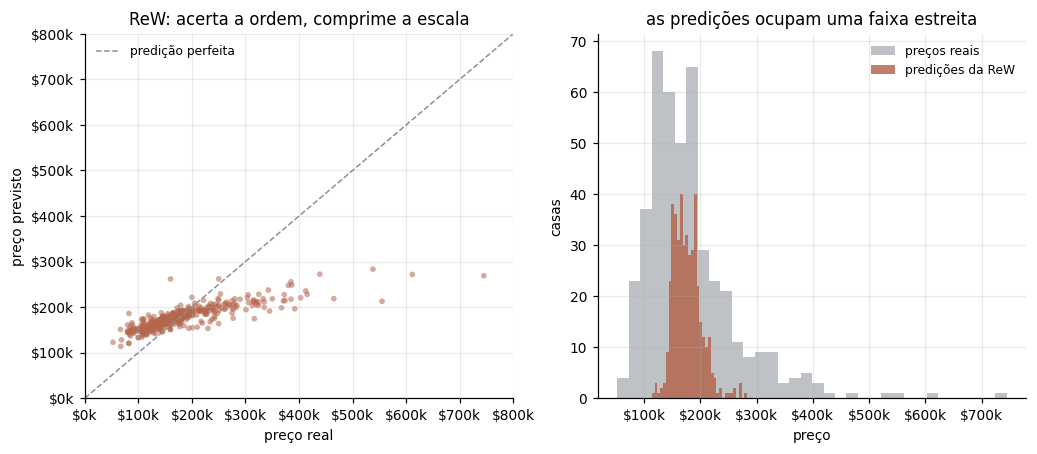

In [9]:
fig, ax = plt.subplots(1, 2, figsize=(9.5, 4.2))

lim = [0, 800000]
ax[0].plot(lim, lim, color=COR_REF, lw=1, ls="--", label="predição perfeita")
ax[0].scatter(yte, yp_rew, s=14, alpha=.55, color=COR_REW, edgecolor="none")
ax[0].set(xlabel="preço real", ylabel="preço previsto", xlim=lim, ylim=lim,
          title="ReW: acerta a ordem, comprime a escala")
ax[0].legend(frameon=False, fontsize=8)
ax[0].xaxis.set_major_formatter(lambda v, p: f"${v/1000:.0f}k")
ax[0].yaxis.set_major_formatter(lambda v, p: f"${v/1000:.0f}k")

ax[1].hist(yte, bins=34, alpha=.55, color=COR_REF, label="preços reais")
ax[1].hist(yp_rew, bins=34, alpha=.85, color=COR_REW, label="predições da ReW")
ax[1].set(xlabel="preço", ylabel="casas", title="as predições ocupam uma faixa estreita")
ax[1].legend(frameon=False, fontsize=8)
ax[1].xaxis.set_major_formatter(lambda v, p: f"${v/1000:.0f}k")

plt.tight_layout(); plt.show()

### A causa: alguns endereços engolem quase todo o conjunto de treino

A `SimpleMean` é, algebricamente, uma média ponderada em que **o peso de cada RAM
node é o seu contador**:

$$
\hat{y} \;=\; \frac{\sum_k S_k}{\sum_k c_k}
\;=\; \frac{\sum_k c_k \cdot \mu_k}{\sum_k c_k}
\qquad\text{com}\qquad \mu_k = \frac{S_k}{c_k}
$$

E os contadores são muito desiguais. Existem endereços que capturam quase todas
as casas de treino. A estimativa local desses blocos é praticamente a média
global, e o peso deles esmaga as RAM nodes específicas, que são justamente as que
sabem reconhecer uma casa cara.

contador por endereço: mediana 2   máximo 530   (o treino tem 1022 casas)
o maior bloco sozinho contém 52% do conjunto de treino



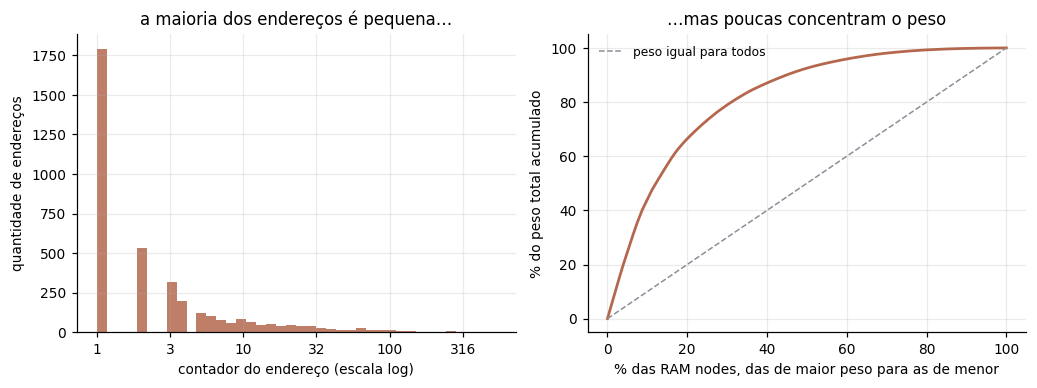

as 10% de RAM nodes com maior contador concentram 44% de todo o peso da votação


In [10]:
todos = np.array([c for m in rew._memory for c, _ in m.values()])
print(f"contador por endereço: mediana {np.median(todos):.0f}   "
      f"máximo {todos.max():.0f}   (o treino tem {len(ytr)} casas)")
print(f"o maior bloco sozinho contém {todos.max()/len(ytr):.0%} do conjunto de treino\n")

# quanto do peso total vai para os maiores blocos
cs, ss = rew._le(Xte)
peso = cs[cs > 0]
ordenado = np.sort(peso)[::-1]
frac = np.cumsum(ordenado) / ordenado.sum()

fig, ax = plt.subplots(1, 2, figsize=(9.5, 3.6))

ax[0].hist(np.log10(todos), bins=40, color=COR_REW, alpha=.85)
ax[0].set(xlabel="contador do endereço (escala log)", ylabel="quantidade de endereços",
          title="a maioria dos endereços é pequena…")
ax[0].xaxis.set_major_formatter(lambda v, p: f"{10**v:.0f}")

ax[1].plot(np.arange(1, len(frac)+1)/len(frac)*100, frac*100, color=COR_REW, lw=1.8)
ax[1].plot([0,100],[0,100], color=COR_REF, ls="--", lw=1, label="peso igual para todos")
ax[1].set(xlabel="% das RAM nodes, das de maior peso para as de menor",
          ylabel="% do peso total acumulado", title="…mas poucas concentram o peso")
ax[1].legend(frameon=False, fontsize=8)

plt.tight_layout(); plt.show()

d10 = frac[max(int(len(frac)*.10)-1, 0)]
print(f"as 10% de RAM nodes com maior contador concentram {d10:.0%} de todo o peso da votação")

---
## 7. A Kalman-ReW

### A ideia

O filtro de Kalman estima uma grandeza a partir de observações sucessivas
ruidosas. Ele guarda dois números: uma estimativa $x$ e uma incerteza $p$. A cada
observação $z$:

$$
\bar{p} = p + q
\qquad
\kappa = \frac{\bar{p}}{\bar{p} + r}
\qquad
x \leftarrow x + \kappa\,(z - x)
\qquad
p \leftarrow (1-\kappa)\,\bar{p}
$$

Os dois parâmetros têm significados diferentes:

- $r$ é o **ruído de observação**: o quanto cada medição individual é imprecisa
- $q$ é o **ruído de processo**: o quanto a grandeza verdadeira se move sozinha entre uma observação e outra

### Onde ele entra na célula

A célula passa a guardar **quatro** números, e os dois primeiros são estados do
filtro:

| campo | observação $z$ | converge para | papel |
|---|---|---|---|
| $c_k$ | $1.0$ fixo | $1$ | **peso** da RAM node na agregação |
| $y_k$ | $y_i$ | média local de $y$ | **estimativa** da RAM node |
| $p_c$, $p_y$ | — | — | incertezas de cada filtro |

O $c_k$ com observação fixa em $1.0$ é exatamente o mecanismo do KalWeNN de
classificação: ele mede o quanto aquele endereço está estabelecido, e **satura**,
em vez de crescer sem limite como o contador.

### Por que a agregação precisa mudar

Na ReW, $S_k$ é uma **soma**: cresce com $c_k$. Por isso $\sum S / \sum c$ é uma
média legítima.

Com Kalman, $y_k$ é um **estado**: já é uma média, não cresce com o número de
visitas. Somar $y_k$ entre RAM nodes e dividir por $\sum c_k$ seria
dimensionalmente errado, o numerador não acompanharia o denominador. A forma
correta é a média ponderada explícita, com os pesos normalizados pela própria
soma:

$$
\boxed{\;\hat{y} \;=\; \frac{\sum_k c_k \cdot y_k}{\sum_k c_k}\;}
\qquad c_k \in [0,1)
$$

A divisão por $\sum c_k$ normaliza os pesos, o que faz o resultado ficar na
escala de $y$ independentemente de quantas RAM nodes contribuíram.

In [11]:
class KalmanReW:
    """Regression WiSARD com filtro de Kalman nos dois estados da célula.

    célula = [c, y, p_c, p_y]
        c : estado de ocupação, observação z=1.0, satura em [0,1) → é o PESO
        y : estado da estimativa, observação z=y_i               → é a ESTIMATIVA

    Predição:  ŷ = Σ c_k·y_k / Σ c_k
    """

    def __init__(self, address_size=17, resolution=16, seed=42,
                 q_c=1e-3, r_c=2.0, q_y=0.0, r_y=1.0, mapping=None):
        self.address_size, self.resolution = address_size, resolution
        self.q_c, self.r_c = q_c, r_c        # filtro do peso
        self.q_y, self.r_y = q_y, r_y        # filtro da estimativa
        self._rng = np.random.default_rng(seed)
        self._mapping_fixo = None if mapping is None else np.asarray(mapping, dtype=int)

    def fit(self, X, y):
        X, y = np.asarray(X, float), np.asarray(y, float)
        self._encoders = build_encoders(X, self.resolution)
        Xb = apply_encoders(X, self._encoders)
        self.retina_size_ = Xb.shape[1]
        self._mapping = (self._mapping_fixo if self._mapping_fixo is not None
                         else monta_mapping(self.retina_size_, self.address_size, self._rng))
        self.n_rams_ = self._mapping.shape[0]
        addr = calcula_addresses(Xb, self._mapping, self.address_size)

        # com q>0 a ordem passa a importar, então embaralhamos (como o KalWeNN faz)
        ordem = self._rng.permutation(len(Xb))

        self._memory = [dict() for _ in range(self.n_rams_)]
        for i in ordem:
            for r in range(self.n_rams_):
                a = int(addr[i, r])
                cel = self._memory[r].get(a)

                if cel is None:
                    # primeira visita.
                    #   peso: parte de 0 e recebe a primeira observação z=1
                    pc = 1.0 + self.q_c
                    kc = pc / (pc + self.r_c)
                    #   estimativa: prior não informativo, aceita o valor de face.
                    #   No limite p0→∞ tem-se κ→1, logo y=z e p=r. Calcular pelo
                    #   limite evita o cancelamento catastrófico de (1-κ).
                    self._memory[r][a] = [kc, y[i], (1.0 - kc) * pc, self.r_y]
                    continue

                # atualiza o PESO com observação z = 1.0
                pc = cel[2] + self.q_c
                kc = pc / (pc + self.r_c)
                cel[0] = cel[0] + kc * (1.0 - cel[0])
                cel[2] = (1.0 - kc) * pc

                # atualiza a ESTIMATIVA com observação z = y_i
                py = cel[3] + self.q_y
                ky = py / (py + self.r_y)
                cel[1] = cel[1] + ky * (y[i] - cel[1])
                cel[3] = (1.0 - ky) * py
        return self

    def predict(self, X):
        Xb = apply_encoders(np.asarray(X, float), self._encoders)
        addr = calcula_addresses(Xb, self._mapping, self.address_size)
        out = np.empty(len(Xb))
        for i in range(len(Xb)):
            num = den = 0.0
            for r in range(self.n_rams_):
                cel = self._memory[r].get(int(addr[i, r]))
                if cel is not None:
                    num += cel[0] * cel[1]     # c_k · y_k
                    den += cel[0]              # c_k
            out[i] = num / den if den > 0 else 0.0
        return out

    def dont_know(self, X):
        Xb = apply_encoders(np.asarray(X, float), self._encoders)
        addr = calcula_addresses(Xb, self._mapping, self.address_size)
        return np.array([
            np.mean([self._memory[r].get(int(addr[i, r])) is None
                     for r in range(self.n_rams_)])
            for i in range(len(Xb))
        ])

### O que a saturação faz com o peso

Antes de rodar, vale ver o efeito isolado. O contador cru cresce sem teto; o
estado $c_k$ satura. É isso que impede um endereço visto mil vezes de valer mil
votos.

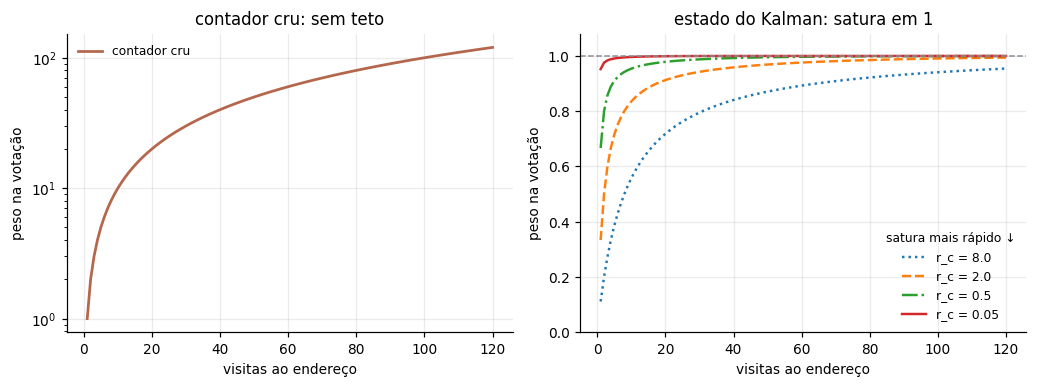

com r_c pequeno o peso satura quase de imediato: 1 visita já vale quase tanto quanto 100
com r_c grande a saturação é lenta e o comportamento se aproxima do contador cru


In [12]:
def satura(n, q, r):
    """Valor do estado c depois de n visitas (observação sempre 1.0)."""
    x, p, hist = 0.0, 1.0, []
    for _ in range(int(n)):
        pp = p + q
        k = pp / (pp + r)
        x += k * (1.0 - x)
        p = (1 - k) * pp
        hist.append(x)
    return hist

ns = np.arange(1, 121)
fig, ax = plt.subplots(1, 2, figsize=(9.5, 3.6))

ax[0].plot(ns, ns, color=COR_REW, lw=1.8, label="contador cru")
ax[0].set(xlabel="visitas ao endereço", ylabel="peso na votação",
          title="contador cru: sem teto", yscale="log")
ax[0].legend(frameon=False, fontsize=8)

for rc, ls in [(8.0, ":"), (2.0, "--"), (0.5, "-."), (0.05, "-")]:
    ax[1].plot(ns, satura(120, 1e-3, rc)[:120], lw=1.6, ls=ls, label=f"r_c = {rc}")
ax[1].axhline(1.0, color=COR_REF, lw=1, ls="--")
ax[1].set(xlabel="visitas ao endereço", ylabel="peso na votação",
          title="estado do Kalman: satura em 1", ylim=(0, 1.08))
ax[1].legend(frameon=False, fontsize=8, title="satura mais rápido ↓", title_fontsize=8)

plt.tight_layout(); plt.show()

print("com r_c pequeno o peso satura quase de imediato: 1 visita já vale quase tanto quanto 100")
print("com r_c grande a saturação é lenta e o comportamento se aproxima do contador cru")

---
## 8. Comparação: ReW contra Kalman-ReW

Tudo fixo entre os modelos: mesmo `address_size`, mesmo thermometer, mesmas
seeds, mesmo split. A única coisa que muda é como a predição é montada a partir
das células.

A última linha é uma **referência**, não um modelo proposto: é o que acontece se
o peso for simplesmente 1 para toda RAM node. Ela existe para responder se o
Kalman está entregando algo além de "limitar o peso".

In [13]:
linhas = [dict(modelo="ReW", **avalia(
    lambda s: RegressionWiSARD(ADDRESS_SIZE, RESOLUTION, seed=s, mean=SimpleMean())))]

for rc in [8.0, 2.0, 0.5, 0.05]:
    linhas.append(dict(modelo=f"Kalman-ReW (r_c={rc})", **avalia(
        lambda s, rc=rc: KalmanReW(ADDRESS_SIZE, RESOLUTION, seed=s,
                                   q_c=1e-3, r_c=rc, q_y=0.0, r_y=1.0))))

linhas.append(dict(modelo="[referência] peso uniforme", **avalia(
    lambda s: RegressionWiSARD(ADDRESS_SIZE, RESOLUTION, seed=s, mean=UnweightedMean()))))

tabela = pd.DataFrame(linhas)
print(tabela.to_string(index=False,
      float_format=lambda v: f"{v:,.4f}" if abs(v) < 10 else f"{v:,.0f}"))

                    modelo    MAE  MAE_dp   RMSE     R2  amplitude
                       ReW 37,359   2,964 56,238 0.4904     0.3697
      Kalman-ReW (r_c=8.0) 29,994   2,038 46,047 0.6588     0.5070
      Kalman-ReW (r_c=2.0) 28,650   1,945 43,687 0.6928     0.5410
      Kalman-ReW (r_c=0.5) 27,980   1,896 42,407 0.7105     0.5612
     Kalman-ReW (r_c=0.05) 27,681   1,857 41,811 0.7184     0.5717
[referência] peso uniforme 27,644   1,852 41,736 0.7194     0.5732


### Os mesmos números em gráfico

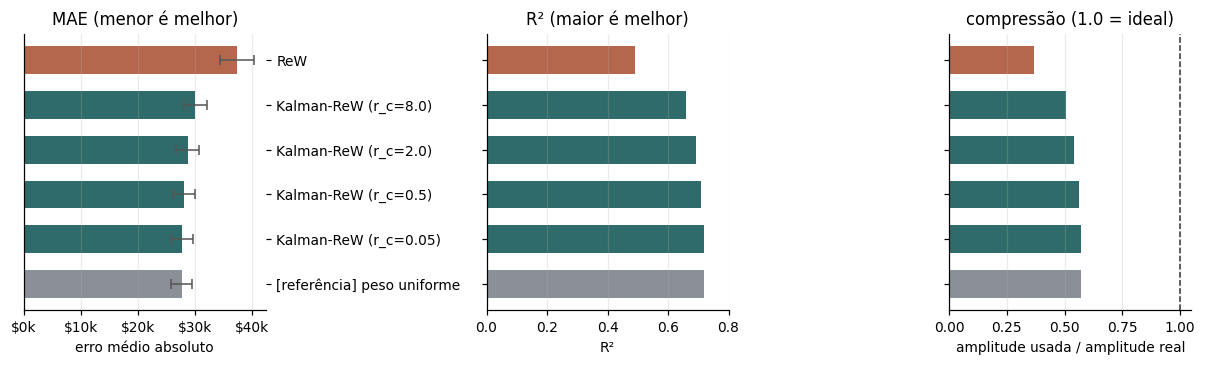

In [14]:
nomes = tabela["modelo"].tolist()
cores = [COR_REW] + [COR_KAL]*4 + [COR_REF]
ypos = np.arange(len(nomes))[::-1]

fig, ax = plt.subplots(1, 3, figsize=(11, 3.4), sharey=True)

ax[0].barh(ypos, tabela["MAE"], xerr=tabela["MAE_dp"], color=cores,
           height=.62, error_kw=dict(lw=1, capsize=3, ecolor="#555"))
ax[0].set(yticks=ypos, yticklabels=nomes, xlabel="erro médio absoluto",
          title="MAE (menor é melhor)")
ax[0].xaxis.set_major_formatter(lambda v, p: f"${v/1000:.0f}k")
ax[0].invert_xaxis(); ax[0].yaxis.tick_right(); ax[0].invert_xaxis()

ax[1].barh(ypos, tabela["R2"], color=cores, height=.62)
ax[1].set(xlabel="R²", title="R² (maior é melhor)", xlim=(0, .8))

ax[2].barh(ypos, tabela["amplitude"], color=cores, height=.62)
ax[2].axvline(1.0, color="#333", lw=1, ls="--")
ax[2].set(xlabel="amplitude usada / amplitude real", title="compressão (1.0 = ideal)",
          xlim=(0, 1.05))

for a in ax:
    a.grid(axis="y", visible=False)
plt.tight_layout(); plt.show()

### O efeito visto sobre as predições

O mesmo gráfico de dispersão da seção 6, agora com os dois modelos lado a lado.

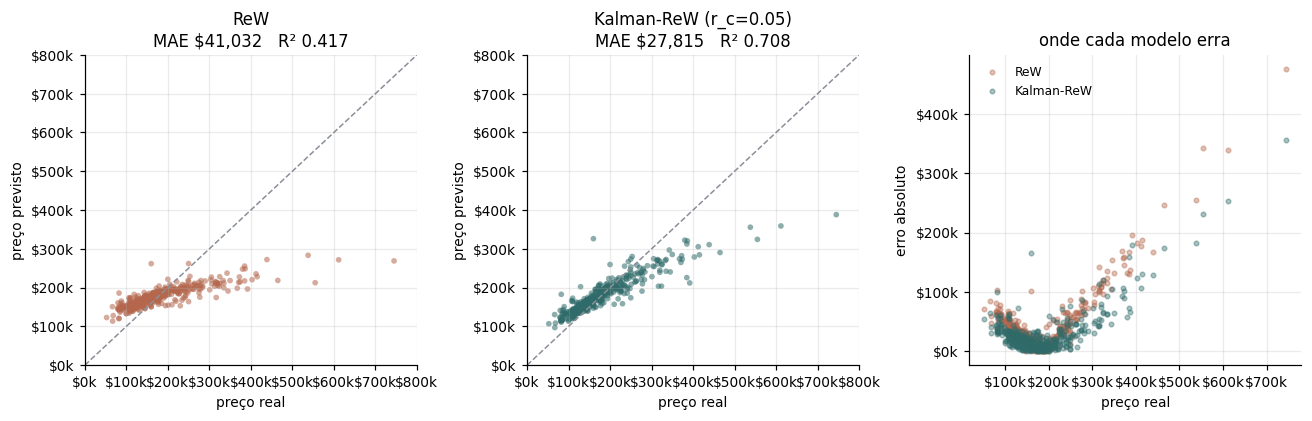

ReW        : MAE $  41,032   amplitude usada 30.6%
Kalman-ReW : MAE $  27,815   amplitude usada 55.7%


In [15]:
kal = KalmanReW(ADDRESS_SIZE, RESOLUTION, seed=0, q_c=1e-3, r_c=0.05,
                q_y=0.0, r_y=1.0).fit(Xtr, ytr)
yp_kal = kal.predict(Xte)

fig, ax = plt.subplots(1, 3, figsize=(12, 3.9))
lim = [0, 800000]

for a, yp, cor, tit in [(ax[0], yp_rew, COR_REW, "ReW"),
                        (ax[1], yp_kal, COR_KAL, "Kalman-ReW (r_c=0.05)")]:
    a.plot(lim, lim, color=COR_REF, lw=1, ls="--")
    a.scatter(yte, yp, s=14, alpha=.55, color=cor, edgecolor="none")
    a.set(xlabel="preço real", ylabel="preço previsto", xlim=lim, ylim=lim,
          title=f"{tit}\nMAE ${mae(yte, yp):,.0f}   R² {r2(yte, yp):.3f}")
    a.xaxis.set_major_formatter(lambda v, p: f"${v/1000:.0f}k")
    a.yaxis.set_major_formatter(lambda v, p: f"${v/1000:.0f}k")

erro_rew = np.abs(yte - yp_rew)
erro_kal = np.abs(yte - yp_kal)
ordem = np.argsort(yte)
ax[2].plot(yte[ordem], np.abs(erro_rew[ordem]), lw=0, marker="o", ms=3,
           alpha=.4, color=COR_REW, label="ReW")
ax[2].plot(yte[ordem], np.abs(erro_kal[ordem]), lw=0, marker="o", ms=3,
           alpha=.4, color=COR_KAL, label="Kalman-ReW")
ax[2].set(xlabel="preço real", ylabel="erro absoluto", title="onde cada modelo erra")
ax[2].legend(frameon=False, fontsize=8)
ax[2].xaxis.set_major_formatter(lambda v, p: f"${v/1000:.0f}k")
ax[2].yaxis.set_major_formatter(lambda v, p: f"${v/1000:.0f}k")

plt.tight_layout(); plt.show()

print(f"ReW        : MAE ${mae(yte, yp_rew):>8,.0f}   amplitude usada {yp_rew.std()/yte.std():.1%}")
print(f"Kalman-ReW : MAE ${mae(yte, yp_kal):>8,.0f}   amplitude usada {yp_kal.std()/yte.std():.1%}")

---
## 9. O que os resultados dizem

**1. O Kalman melhora a ReW, e bastante.** O MAE cai cerca de 26% e o R² sobe de
aproximadamente 0,49 para 0,72. O desvio entre seeds também cai, ou seja, o
modelo fica mais estável, além de mais preciso.

**2. O mecanismo é a limitação do peso, não a filtragem da estimativa.** O
filtro no estado $y_k$, sozinho, com o peso continuando a ser o contador cru, não
muda nada: com $q_y = 0$ ele reproduz a ReW exatamente, porque o ganho vira
$\kappa_j = 1/j$, que é a fórmula incremental da média. Todo o efeito vem do
estado $c_k$ saturado servindo de peso normalizado.

**3. O ganho é monotônico em $r_c$, e o limite é o peso uniforme.** Quanto mais o
peso satura, melhor o resultado, e a última linha da tabela mostra onde essa
sequência termina: com peso 1 para todos. O Kalman se aproxima desse limite por
baixo sem ultrapassá-lo.

Isso significa que, **neste dataset**, o filtro entrega quase todo o ganho
disponível, mas a forma mais simples possível de limitar o peso entrega o mesmo.
A vantagem do Kalman aqui é ser um mecanismo contínuo e ajustável entre os dois
extremos, não uma melhora sobre ambos.

**4. O que ainda não foi testado.** O parâmetro $q_y$ (esquecimento na estimativa
de $y$) só tem o que fazer se a relação entre entrada e saída **mudar ao longo do
tempo**. O House Prices é uma tabela estática, sem ordem temporal com
significado, então aqui $q_y > 0$ só introduz dependência da ordem de
embaralhamento. Testar isso exige um dataset com estrutura temporal real, que é
justamente o cenário que os artigos da ReW citam como motivação (sensores
aprendendo em operação) e nunca testaram.

A célula abaixo demonstra o ponto 2, que é o mais fácil de confundir.

In [16]:
# Kalman SÓ na estimativa (peso continua sendo o contador cru): nada muda
class KalmanSoNoY(RegressionWiSARD):
    """Filtra y_k, mas mantém o contador cru como peso. Serve para isolar o efeito."""

    def __init__(self, *a, q_y=0.0, r_y=1.0, **kw):
        super().__init__(*a, **kw)
        self.q_y, self.r_y = q_y, r_y

    def fit(self, X, y):
        super().fit(X, y)
        # reconstrói a memória substituindo soma por estado filtrado
        X, y = np.asarray(X, float), np.asarray(y, float)
        Xb = apply_encoders(X, self._encoders)
        addr = calcula_addresses(Xb, self._mapping, self.address_size)
        mem = [dict() for _ in range(self.n_rams_)]
        for i in self._rng.permutation(len(Xb)):
            for r in range(self.n_rams_):
                a = int(addr[i, r])
                cel = mem[r].get(a)
                if cel is None:
                    mem[r][a] = [1.0, y[i], self.r_y]
                    continue
                p = cel[2] + self.q_y
                k = p / (p + self.r_y)
                cel[0] += 1.0
                cel[1] += k * (y[i] - cel[1])
                cel[2] = (1.0 - k) * p
        # guarda como (contador, estado × contador) para a SimpleMean funcionar
        self._memory = [{a: [c[0], c[1] * c[0]] for a, c in m.items()} for m in mem]
        return self


so_y = KalmanSoNoY(ADDRESS_SIZE, RESOLUTION, seed=0, mean=SimpleMean(),
                   q_y=0.0, r_y=1.0).fit(Xtr, ytr)
d = np.abs(rew.predict(Xte) - so_y.predict(Xte)).max()

print(f"ReW  vs  Kalman só na estimativa (peso = contador cru)")
print(f"  maior diferença entre as predições: ${d:,.6f}")
print(f"  → são o mesmo modelo. filtrar y sozinho não faz nada.\n")
print(f"ReW                          MAE ${mae(yte, rew.predict(Xte)):>8,.0f}")
print(f"Kalman só na estimativa      MAE ${mae(yte, so_y.predict(Xte)):>8,.0f}")
print(f"Kalman nos dois estados      MAE ${mae(yte, yp_kal):>8,.0f}   ← aqui muda")

ReW  vs  Kalman só na estimativa (peso = contador cru)
  maior diferença entre as predições: $0.000000
  → são o mesmo modelo. filtrar y sozinho não faz nada.

ReW                          MAE $  41,032
Kalman só na estimativa      MAE $  41,032
Kalman nos dois estados      MAE $  27,815   ← aqui muda
